# 作业3：NumPy、Matplotlib 与 pandas

学号：20244080316  姓名：郑奕欣

In [19]:
import hashlib
import os
import platform
import uuid
import sys

# 填写学号
STUDENT_ID = 20244080316

env_path = sys.executable
if "envs" in env_path:
    CONDA_ENV = env_path.split("envs\\")[1].split("\\")[0]
else:
    CONDA_ENV = "base"
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] hw01
[学号] 20244080316
[机器指纹] 421fc22899a2e25f
[RUN_ID] 20244080316-421fc22899a2e25f


## 一、半圆定律

In [5]:
import numpy as np

def wigner_density(x):
    if x < -2 or x > 2:
        return 0.0
    return float(np.sqrt(4 - x * x) / (2 * np.pi))

In [6]:
def generate_wigner(n):
    if type(n) is not int or n <= 0:
        raise ValueError("n 必须是正整数")

    Z = np.zeros((n, n))
    for i in range(n):
        for j in range(i, n):
            val = np.random.normal(0, 1 / np.sqrt(n))
            Z[i, j] = val
            Z[j, i] = val
    return Z

In [7]:
def get_spectrum(matrix):
    vals = np.linalg.eigvalsh(matrix)
    return np.sort(vals)

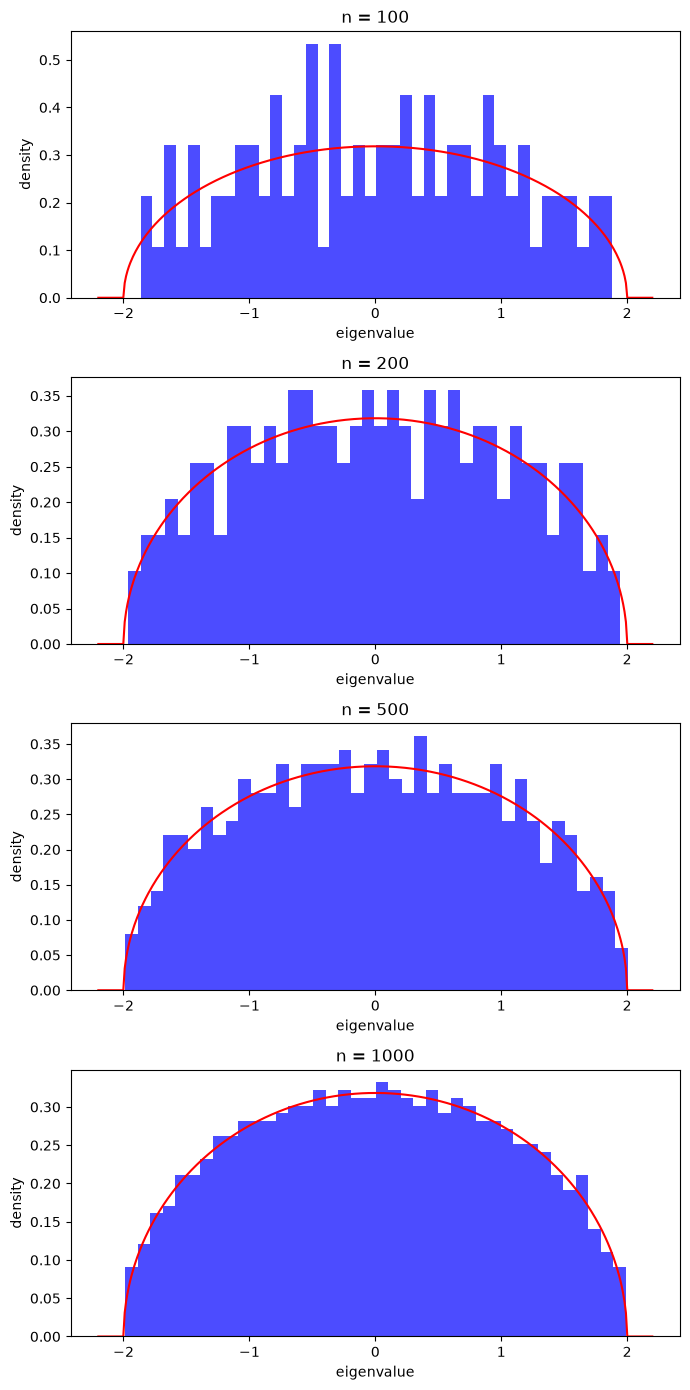

In [8]:
import matplotlib.pyplot as plt

ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(7, 14))

x = np.linspace(-2.2, 2.2, 400)
y = []
for v in x:
    y.append(wigner_density(v))

for k in range(4):
    n = ns[k]
    Z = generate_wigner(n)
    eig = get_spectrum(Z)

    axes[k].hist(eig, bins=40, density=True, color="blue", alpha=0.7)
    axes[k].plot(x, y, color="red")
    axes[k].set_title("n = " + str(n))
    axes[k].set_xlabel("eigenvalue")
    axes[k].set_ylabel("density")

plt.tight_layout()
plt.show()

从图上能看出来，n=100的时候直方图大概有个半圆的形状，但边缘抖得比较厉害。
n=200明显好一些，n=500和n=1000基本上和红色曲线贴得很近了。
所以我感觉n到500左右，半圆密度就拟合得比较好了。

## 二、Conway 的生命游戏

In [9]:
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if len(board.shape) != 2:
        return False
    for row in board:
        for cell in row:
            if cell != 0 and cell != 1:
                return False
    return True

In [10]:
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("棋盘不合法")

    m = board.shape[0]
    n = board.shape[1]
    new_board = np.zeros((m, n), dtype=int)

    for i in range(m):
        for j in range(n):
            count = 0
            for di in [-1, 0, 1]:
                for dj in [-1, 0, 1]:
                    if di == 0 and dj == 0:
                        continue
                    ni = (i + di) % m
                    nj = (j + dj) % n
                    count += board[ni, nj]

            if board[i, j] == 1:
                if count == 2 or count == 3:
                    new_board[i, j] = 1
            else:
                if count == 3:
                    new_board[i, j] = 1

    return new_board

In [11]:
def draw_gol_board(board):
    plt.imshow(board, cmap=plt.get_cmap("binary"), interpolation="nearest")
    plt.xticks([])
    plt.yticks([])
    plt.axis("off")
    plt.show()

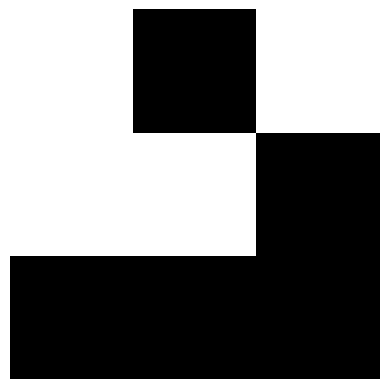

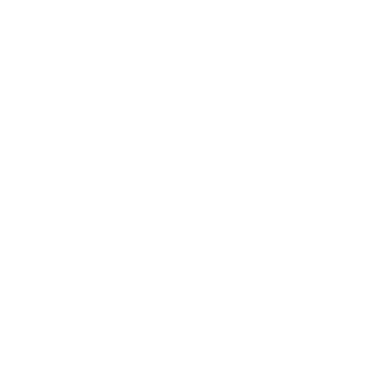

In [12]:
glider = np.array([[0, 1, 0],
                   [0, 0, 1],
                   [1, 1, 1]])
draw_gol_board(glider)
draw_gol_board(gol_step(glider))

## 三、使用 pandas DataFrame

In [ ]:
import pandas as pd

df = pd.read_csv("Iris.csv")

df = df.drop(columns=['Unnamed: 0'])

df.columns = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

species_list = ['setosa'] * 50 + ['versicolor'] * 50 + ['virginica'] * 50
df['species'] = species_list

print(df.shape)
print(df.columns.tolist())

(150, 5)
['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'species']


数据集一共150个数据点，5列。
前四列是浮点数（float64），最后一列是字符串（object）。
列名是sepal_length, sepal_width, petal_length, petal_width, species。
species这一列有3种花。

In [ ]:
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]

print(df.loc[[34, 37]])

    sepal_length  sepal_width  petal_length  petal_width species
34           4.9          3.1           1.5          0.2  setosa
37           4.9          3.6           1.4          0.1  setosa


In [15]:
df["Petal.Ratio"] = df["petal_length"] / df["petal_width"]
df["Sepal.Ratio"] = df["sepal_length"] / df["sepal_width"]

In [16]:
df.to_csv("iris_corrected.csv", index=False)

In [17]:
res = df.groupby("species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
print(res)

           Petal.Ratio                                     Sepal.Ratio  \
                  mean    median       min   max       std        mean   
species                                                                  
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.471380   
versicolor    3.182408  3.230769  0.335714   4.1  0.515861    2.165531   
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453   

                                                    
              median       min       max       std  
species                                             
setosa      1.466667  1.268293  1.956522  0.119677  
versicolor  2.161290  1.764706  2.818182  0.228104  
virginica   2.169540  1.823529  2.961538  0.246992  
